# 02 · Model comparison and baselines

The target is the proxy label `High_Admission_Chance` (the dataset's estimated Chance of Admit at or
above a target threshold), not an admission decision. This notebook works at the default target
threshold of 0.75; notebook 03 repeats everything at 0.70 and 0.80.

**Protocol.** `RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)` gives 50
validation folds. Every baseline and model is scored on the same 50 folds. Hyperparameters are tuned
by an inner 5-fold grid search on the training fold only (nested cross-validation), and scalers live
inside each pipeline. Balanced accuracy is the selection metric.

The full run for all five model families is `python scripts/evaluate_models.py`. Here the baselines
and one model are re-run live and checked against the committed fold scores; the remaining models are
read from `outputs/repeated_cv_fold_scores.csv`.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "gradmit").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
TEAL, OCHRE, SLATE, BRICK = "#0B6E69", "#B7791F", "#6B7C80", "#B4452F"

from gradmit.baselines import CGPA_CUTOFF, MAJORITY, CGPACutoffClassifier, select_cgpa_cutoff
from gradmit.data import DEFAULT_TARGET_THRESHOLD, FEATURES, load_data, make_target
from gradmit.evaluation import METRICS, cv_splits, summarise_folds
from gradmit.modelling import MODEL_NAMES, evaluate_threshold, model_specs, select_model
from gradmit.reporting import load_outputs

THR = DEFAULT_TARGET_THRESHOLD
df = load_data()
X, y = df[FEATURES], make_target(df, THR).to_numpy()
outputs = load_outputs()
committed = outputs["folds"][np.isclose(outputs["folds"].target_threshold, THR)]
splits = cv_splits(X, y)
print(len(splits), "validation folds; fold sizes:", sorted({len(s["test"]) for s in splits}))
assert all(len(np.intersect1d(s["train"], s["test"])) == 0 for s in splits)

50 validation folds; fold sizes: [100]


## Baselines on the same folds

- **Majority baseline:** `DummyClassifier(strategy="most_frequent")`.
- **CGPA cutoff baseline:** predict positive when `CGPA >= cutoff`. For each fold the cutoff is chosen
  on the training rows to maximise training balanced accuracy, then frozen and applied to the
  validation rows.

In [2]:
baseline_folds, baseline_oof = evaluate_threshold(df, THR, models=[MAJORITY, CGPA_CUTOFF], n_jobs=1)

key = ["model", "repeat", "fold"]
check = baseline_folds.merge(committed, on=key, suffixes=("", "_committed"))
assert len(check) == 100
assert np.allclose(check["balanced_accuracy"], check["balanced_accuracy_committed"], atol=2e-6)

n_pos, n = int(y.sum()), len(y)
print(f"positive proxy class: {n_pos}/{n} = {n_pos / n:.1%}; negative: {n - n_pos}/{n} = {(n - n_pos) / n:.1%}")
summarise_folds(baseline_folds)[["model", "accuracy_mean", "balanced_accuracy_mean", "balanced_accuracy_std",
                                 "balanced_accuracy_ci_low", "balanced_accuracy_ci_high", "f1_mean", "roc_auc_mean"]]

positive proxy class: 218/500 = 43.6%; negative: 282/500 = 56.4%


,model,accuracy_mean,balanced_accuracy_mean,balanced_accuracy_std,balanced_accuracy_ci_low,balanced_accuracy_ci_high,f1_mean,roc_auc_mean
0,CGPA cutoff baseline,0.876,0.875,0.027,0.847,0.903,0.859,0.953
1,Majority baseline,0.564,0.500,0.000,0.500,0.500,0.000,0.500


fold 0: cutoff chosen on 400 training rows = 8.655; applied to 100 validation rows


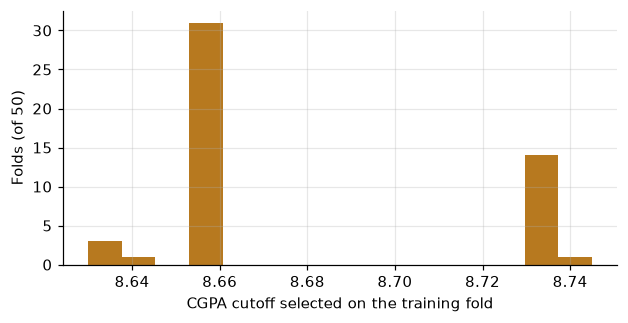

Across the 50 training folds the selected cutoff ranges from 8.63 to 8.75 (median 8.66).

In [3]:
# The cutoff is selected from training rows only. One fold, step by step:
s = splits[0]
cutoff = select_cgpa_cutoff(X["CGPA"].to_numpy()[s["train"]], y[s["train"]])
rule = CGPACutoffClassifier().fit(X.iloc[s["train"]], y[s["train"]])
assert rule.cutoff_ == cutoff and rule.n_train_ == len(s["train"])
print(f"fold 0: cutoff chosen on {len(s['train'])} training rows = {cutoff:.3f}; applied to {len(s['test'])} validation rows")

cutoffs = baseline_folds.loc[baseline_folds.model == CGPA_CUTOFF, "cgpa_cutoff"]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(cutoffs, bins=15, color=OCHRE)
ax.set(xlabel="CGPA cutoff selected on the training fold", ylabel="Folds (of 50)")
plt.show()
display(Markdown(f"Across the 50 training folds the selected cutoff ranges from {cutoffs.min():.2f} to "
                 f"{cutoffs.max():.2f} (median {cutoffs.median():.2f})."))

## Candidate model pipelines

In [4]:
pd.DataFrame([{"model": name, "pipeline steps": " -> ".join(type(step).__name__ for _, step in pipe.steps),
               "hyperparameter grid (tuned on the training fold)": grid}
              for name, (pipe, grid) in model_specs().items()]).style.hide(axis="index")

model,pipeline steps,hyperparameter grid (tuned on the training fold)
Logistic Regression,StandardScaler -> LogisticRegression,"{'model__C': [0.1, 1.0, 10.0]}"
Random Forest,RandomForestClassifier,"{'model__max_depth': [4, None], 'model__min_samples_leaf': [1, 5]}"
Hist Gradient Boosting,HistGradientBoostingClassifier,"{'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]}"
SVM (RBF),StandardScaler -> CalibratedClassifierCV,"{'model__estimator__C': [0.1, 1.0, 10.0]}"
K-Nearest Neighbours,StandardScaler -> KNeighborsClassifier,"{'model__n_neighbors': [5, 11, 21], 'model__weights': ['uniform', 'distance']}"


## One model re-run live

Logistic Regression is re-evaluated here with the full nested protocol (50 outer folds, inner grid
search) and compared fold by fold with the committed scores.

In [5]:
lr_folds, _ = evaluate_threshold(df, THR, models=["Logistic Regression"], n_jobs=1)
check = lr_folds.merge(committed, on=key, suffixes=("", "_committed"))
max_gap = float((check["balanced_accuracy"] - check["balanced_accuracy_committed"]).abs().max())
assert len(check) == 50 and max_gap < 2e-6
print(f"50 live folds match the committed fold scores (largest absolute difference {max_gap:.1e})")
lr_folds["best_params"].value_counts().rename("folds choosing this setting").to_frame()

50 live folds match the committed fold scores (largest absolute difference 4.7e-07)


,folds choosing this setting
best_params,
"{""model__C"": 10.0}",30
"{""model__C"": 1.0}",17
"{""model__C"": 0.1}",3


## Repeated-CV results for every model

In [6]:
comparison = summarise_folds(committed)
assert np.allclose(comparison["balanced_accuracy_mean"],
                   outputs["comparison"][np.isclose(outputs["comparison"].target_threshold, THR)]["balanced_accuracy_mean"], atol=2e-6)
cols = ["model"] + [f"{m}_mean" for m in METRICS] + ["balanced_accuracy_std", "balanced_accuracy_ci_low", "balanced_accuracy_ci_high"]
comparison[cols].rename(columns=lambda c: c.replace("_mean", "")).style.format(precision=3).hide(axis="index")

model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,brier,balanced_accuracy_std,balanced_accuracy_ci_low,balanced_accuracy_ci_high
Logistic Regression,0.885,0.881,0.884,0.850,0.865,0.960,0.081,0.032,0.847,0.915
Random Forest,0.884,0.879,0.889,0.840,0.862,0.957,0.084,0.034,0.843,0.914
Hist Gradient Boosting,0.879,0.875,0.877,0.845,0.859,0.954,0.088,0.033,0.841,0.910
CGPA cutoff baseline,0.876,0.875,0.855,0.868,0.859,0.953,nan,0.027,0.847,0.903
SVM (RBF),0.874,0.868,0.885,0.821,0.850,0.950,0.090,0.030,0.837,0.900
K-Nearest Neighbours,0.871,0.866,0.872,0.828,0.848,0.948,0.091,0.026,0.839,0.893
Majority baseline,0.564,0.500,0.000,0.000,0.000,0.500,0.436,0.000,0.500,0.500


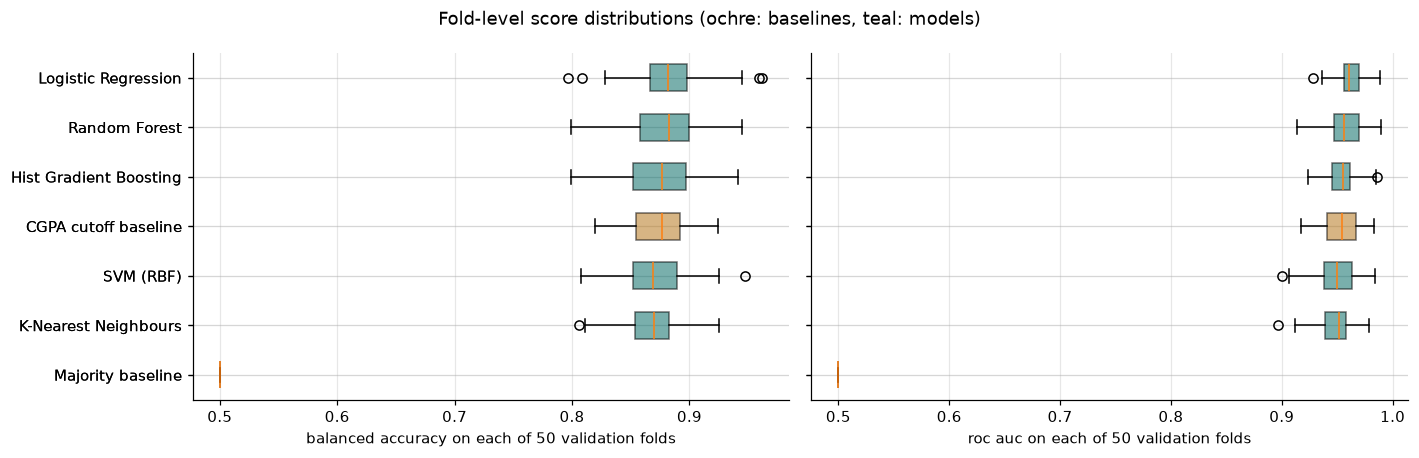

In [7]:
order = comparison["model"].tolist()[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, metric in zip(axes, ["balanced_accuracy", "roc_auc"]):
    data = [committed.loc[committed.model == m, metric].dropna() for m in order]
    bp = ax.boxplot(data, orientation="horizontal", tick_labels=order, patch_artist=True, widths=0.55)
    for patch, m in zip(bp["boxes"], order):
        patch.set(facecolor=OCHRE if m in (MAJORITY, CGPA_CUTOFF) else TEAL, alpha=0.55)
    ax.set_xlabel(f"{metric.replace('_', ' ')} on each of 50 validation folds")
fig.suptitle("Fold-level score distributions (ochre: baselines, teal: models)")
plt.tight_layout(); plt.show()

## Model selection

In [8]:
selected = select_model(comparison, THR)
assert selected == outputs["evaluation"]["selected_model"]
rows = comparison.set_index("model")
ml = rows.loc[list(MODEL_NAMES)].sort_values("balanced_accuracy_mean", ascending=False)
best, runner_up, cgpa = ml.iloc[0], ml.iloc[1], rows.loc[CGPA_CUTOFF]
display(Markdown(
    f"**Selected: {selected}.** It has the highest mean balanced accuracy over the 50 validation folds: "
    f"{best.balanced_accuracy_mean:.3f} (SD {best.balanced_accuracy_std:.3f}, 95% CI "
    f"{best.balanced_accuracy_ci_low:.3f} to {best.balanced_accuracy_ci_high:.3f}).\n\n"
    f"- The runner-up, {ml.index[1]}, is at {runner_up.balanced_accuracy_mean:.3f}; the gap of "
    f"{best.balanced_accuracy_mean - runner_up.balanced_accuracy_mean:.3f} is far smaller than the fold-to-fold SD, "
    "so the ranking among model families is not meaningful.\n"
    f"- The CGPA cutoff baseline reaches {cgpa.balanced_accuracy_mean:.3f} "
    f"(95% CI {cgpa.balanced_accuracy_ci_low:.3f} to {cgpa.balanced_accuracy_ci_high:.3f}). Whether the selected "
    "model improves on it is tested with a paired method in notebook 03.\n"
    f"- The majority baseline has accuracy {rows.loc[MAJORITY].accuracy_mean:.3f} and balanced accuracy "
    f"{rows.loc[MAJORITY].balanced_accuracy_mean:.3f}."))

**Selected: Logistic Regression.** It has the highest mean balanced accuracy over the 50 validation folds: 0.881 (SD 0.032, 95% CI 0.847 to 0.915).

- The runner-up, Random Forest, is at 0.879; the gap of 0.002 is far smaller than the fold-to-fold SD, so the ranking among model families is not meaningful.
- The CGPA cutoff baseline reaches 0.875 (95% CI 0.847 to 0.903). Whether the selected model improves on it is tested with a paired method in notebook 03.
- The majority baseline has accuracy 0.564 and balanced accuracy 0.500.

**Rationale and caveats.** The choice uses development cross-validation only; no single held-out
split is involved. Intervals are Nadeau-Bengio corrected because the 50 folds share training data.
Picking the best of five families on the same outer folds makes the winner's score slightly
optimistic, which is one more reason to judge it against the baselines with a paired test rather than
by its headline number.